In [9]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator

In [10]:
def half_adder():
    # 2 input qubits + 2 output qubits
    qc = QuantumCircuit(4)

    # q0 = x0
    # q1 = x1
    # q2 = Sum
    # q3 = Carry

    # Sum = x0 XOR x1
    qc.cx(0, 2)
    qc.cx(1, 2)

    # Carry = x0 AND x1
    qc.ccx(0, 1, 3)

    return qc

In [11]:
oracle = half_adder()
simulator = AerSimulator()

Adding bits = 00, Carry-Sum = 00, Decimal = 0


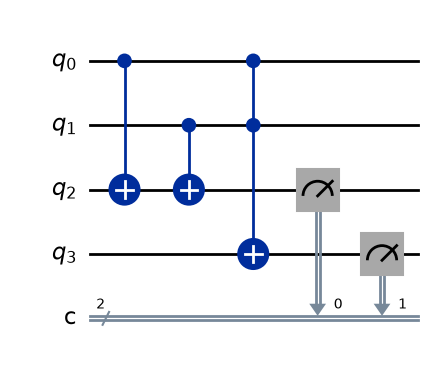

Adding bits = 01, Carry-Sum = 01, Decimal = 1


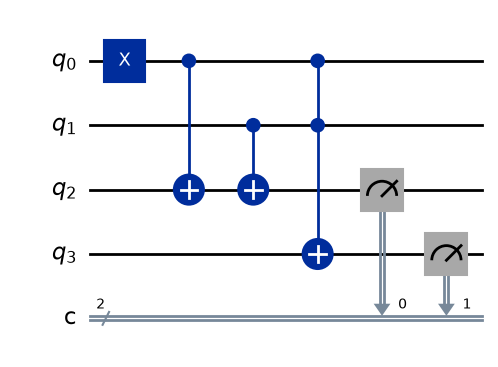

Adding bits = 10, Carry-Sum = 01, Decimal = 1


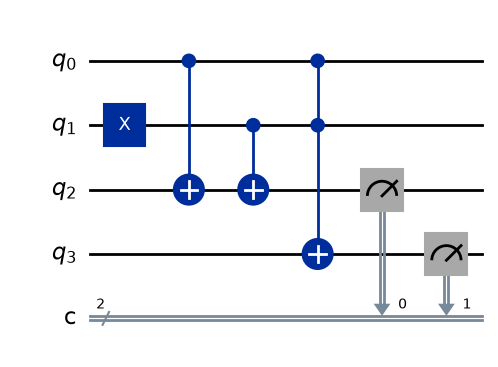

Adding bits = 11, Carry-Sum = 10, Decimal = 2


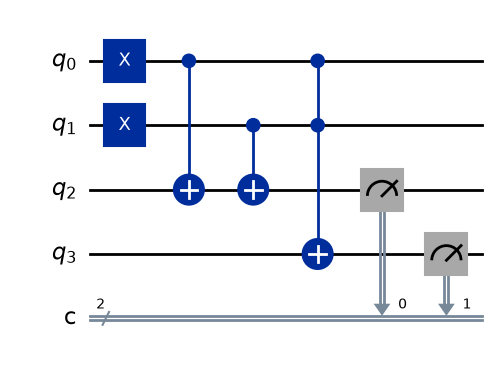

In [12]:
for x in range(4):
    qc = QuantumCircuit(4, 2)

    # Encode input
    for i in range(2):
        if (x >> i) & 1:
            qc.x(i)

    # Apply function
    qc.compose(oracle, inplace=True)

    # Measure output
    qc.measure([2, 3], [0, 1])

    result = simulator.run(transpile(qc, simulator), shots=1).result()
    bits = next(iter(result.get_counts()))
    output = int(bits, 2)
    print(f"Adding bits = {x:02b}, Carry-Sum = {bits}, Decimal = {output}")

    display(qc.draw(output='mpl'))